# A Pool Reactor for Loss-of-Flow Analysis

The reactor on this page is an open-pool research reactor. Its plate core sits 8 m under the pool surface and is cooled by forced flow running downward through four groups of plate channels. Below the core a plenum collects the flow and sends it to a decay tank, then to two pump legs in parallel, each with a pump, a flywheel and a check valve, and on through the heat exchanger back to the pool. A flapper joins the plenum below the core to the bottom of the pool beside it: it is held shut by the pressure of the forced flow and opens when that flow is lost. The pool itself is the heat sink for the natural circulation that follows.

The whole loop is built from the library's components and shipped as `stream.examples.lofa`; the previous page, [Building the Pool Reactor Loop](LOFABuildingTheLoop.ipynb), puts it together by hand, and `build` makes the same loop in one call. The next two examples take it through a loss of flow: both pumps tripping, from coastdown through the reactor trip and the flapper opening to natural circulation, and then the variations (one pump, a flapper that does not open) and how far the numbers can be trusted.

Every transient starts from a steady state, so this page takes the loop `build` makes, solves its operating point, and checks that operating point against estimates one can make by hand.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import rc

rc("font", family="serif", size=15)

from stream.aggregator import Solution
from stream.examples.lofa import Params, junction_mass_balance, operating_point
from stream.examples.lofa.params import CORE, HEATED, nominal_flows, plate_pipe, power_share

## Parameters

`Params` holds the operating point and the modelling choices, all with defaults. Only a few of them set the character of the plant: the core makes 10 MW, the heat exchanger returns the water at 38 °C, there are 8 m of water above the core, each of the two pump legs carries half the core flow, and the flapper opens once the flow returning from the heat exchanger falls to 30 % of the nominal core flow: the flapper and the reactor trip both read the flow of the riser. The table also gives the pump head the loop's losses were estimated to need at nominal flow, before any pump curve is attached.

In [2]:
p = Params()
total = nominal_flows(p)["total"]
pd.Series(
    {
        "power [MW]": p.power / 1e6,
        "heat exchanger outlet [°C]": p.hx_outlet,
        "water above the core [m]": p.core_depth,
        "nominal core flow [kg/s]": total,
        "flow per pump leg [kg/s]": total / 2,
        "flapper opens at [kg/s]": p.flapper_fraction * total,
        "estimated loop head [bar]": p.pump_head_estimate / 1e5,
    }
).round(3).to_frame("value")

,value
power [MW],10.000
heat exchanger outlet [°C],38.000
water above the core [m],8.000
nominal core flow [kg/s],241.532
flow per pump leg [kg/s],120.766
flapper opens at [kg/s],72.460
estimated loop head [bar],0.815


## The core

The core is described by four groups of plates. There are 300 normal plates, a single hot plate carrying 1.6 times the power of a normal one, 90 low plates carrying half of it, and 10 wider unheated channels forming a bypass. The heated plates have a 2.2 mm coolant gap and the bypass 10 mm.

![The four core groups as plate stacks between the pool top and the plenum, and as four parallel edges of the flow graph](_static/lofa/lofa-core.svg)

*One channel and one plate per group; the edge weight `signify` is the plate count.*

Simulating 401 channels one by one would be wasteful, as plates of a group behave identically. Each group is therefore one channel, one plate, and one edge in the flow network, and that edge carries a `signify` weight equal to the group's plate count: the edge's flow is the flow of one plate, and the junctions it connects see that flow multiplied by the plate count. The table below gives the share of the core power each single plate receives and the per-plate flow of the design point. That flow is an estimate, the channel's area times the square root of its hydraulic diameter anchored at 0.5 kg/s for a 2.2 mm gap; it sizes the pumps and the initial guess, and is not the law the solved steady state is checked against below.

In [3]:
flows = nominal_flows(p)
pd.DataFrame(
    {
        "plates": [g.plates for g in CORE.values()],
        "gap [mm]": [g.gap * 1e3 for g in CORE.values()],
        "power factor": [g.factor for g in CORE.values()],
        "power per plate [kW]": [power_share(k) * p.power / 1e3 for k in CORE],
        "flow per plate [kg/s]": [flows[k] for k in CORE],
    },
    index=list(CORE),
).round(3)

,plates,gap [mm],power factor,power per plate [kW],flow per plate [kg/s]
hot,1,2.2,1.6,46.163,0.500
normal,300,2.2,1.0,28.852,0.500
low,90,2.2,0.5,14.426,0.500
bypass,10,10.0,0.0,0.000,4.603


## The loop as a graph

`build` returns the aggregator, the Kirchhoff calculation that holds the flows and pressures of the network, and a dictionary of references to the components. Without kinetics every plate is fed a constant share of the nominal power, which is what the thermal-hydraulic steady state needs. The figure shows the loop it builds, in elevation; [Building the Pool Reactor Loop](LOFABuildingTheLoop.ipynb) builds it component by component and draws the flow graph. The four core groups are the parallel edges from the pool top to the plenum; the flapper runs from the pool bottom to the plenum, so when it opens the core and the flapper form a loop through the pool.

![The pool reactor's loop in elevation, from the pool surface down to the pumps](_static/lofa/lofa-loop.svg)

*The loop `build` makes, in elevation: seven junctions, twelve edges, the pool as the free surface.*

## The operating point

`operating_point` solves the steady state in two stages. First the thermal-hydraulics, with the plates at constant power, from the rough guess described in [A first solve](LOFABuildingTheLoop.ipynb#A-first-solve). Then the point-kinetics node is attached, its temperature-feedback references taken at the solved temperatures, so that the full system starts with zero reactivity and exactly at its operating point. It returns the full system and its consistent state vector `y`.

In [4]:
agr, K, refs, y = operating_point(p)
state = agr.save(y)
state.to_dataframe().head()

,calculation,variable,i,j,value
0,J_pool_top,Tin,0,0,38.000000
1,HotChannel,T_cool,0,0,38.566275
2,HotChannel,T_cool,0,1,40.209596
3,HotChannel,T_cool,0,2,42.768888
4,HotChannel,T_cool,0,3,45.993295


## Hand checks

Three things about this steady state can be estimated without the code: the outlet temperature of each heated channel, how the flow divides between the groups, and the pump heads. `operating_point` stores these checks of the thermal-hydraulic solve in `refs["th_checks"]`.

In [5]:
chk = refs["th_checks"]
print(f"core inlet temperature:        {chk['T_in']:.2f} °C")
print(f"worst outlet temperature error: {chk['T_out_error_max']:.4f} K")
print(f"worst split error:              {100 * chk['split_error_max']:.2f} %")
print(f"pool flow:                      {chk['pool_flow']:.1f} kg/s")
for leg, head in chk["heads"].items():
    curve = float(np.asarray(state[refs["pump_curves"][leg].name]["pressure"]))
    print(f"pump {leg}: head {head / 1e5:.3f} bar, net of its curve {(head + curve) / 1e5:.3f} bar")
law = {k: plate_pipe(g.gap).area * plate_pipe(g.gap).hydraulic_diameter ** (5 / 7) for k, g in CORE.items()}
mdot = chk["mdot"]
pd.DataFrame(
    {
        "flow per plate [kg/s]": mdot,
        "group flow [kg/s]": {k: CORE[k].plates * m for k, m in mdot.items()},
        "flow over 5/7 law": {k: mdot[k] / mdot["normal"] / (law[k] / law["normal"]) for k in CORE},
    }
).round(3)

core inlet temperature:        38.00 °C
worst outlet temperature error: 0.0044 K
worst split error:              3.39 %
pool flow:                      241.5 kg/s
pump A: head 1.278 bar, net of its curve 0.787 bar
pump B: head 1.278 bar, net of its curve 0.787 bar


,flow per plate [kg/s],group flow [kg/s],flow over 5/7 law
hot,0.477,0.477,1.009
normal,0.473,141.915,1.000
low,0.469,42.206,0.991
bypass,5.693,56.933,0.966


**Energy balance.** In each heated channel the water's temperature rise is the plate's power over its flow times the heat capacity, $\Delta T = P / (\dot m c_p)$. The solved outlet temperatures agree with that to within about 0.004 K, although the estimate takes the heat capacity at a single temperature.

**Flow split.** All core groups see the same pressure difference between the pool top and the plenum. With turbulent friction, a channel's flow at a given pressure drop scales as $A\,D_h^{5/7}$, so the per-plate flows should stand in the ratio of that quantity; the last column divides each group's flow by it, normalised to the normal group. This law is sharper than the design-point estimate in the core table, which is why the bypass carries about 5.7 kg/s per channel against its design value of about 4.6 kg/s. The flows follow the law to within about 3.4 %; the largest departure is the bypass, at about 0.97, which differs most from the normal channels in both gap and water temperature. The three heated groups share one geometry, so the law gives them equal flows, yet the hot plate takes about 1 % more than a normal one: its water is warmer and less viscous. The pool, carrying the whole core flow, carries about 242 kg/s.

**Pump heads.** The two pump legs sit in parallel between the same two junctions and are identical, so they share the head and the flow equally: both pumps deliver about 1.28 bar. Net of each pump's droop curve, the head that reaches the loop is about 0.79 bar, close to the estimated loop head of 0.815 bar in the parameter table.

**Mass balance.** The operating point is a steady state, so at every junction the flows in and out must cancel, each core edge counted as many times as its group has plates. The package's conservation checks take a solution of a transient; a single sample of the operating-point vector at time zero is one.

In [6]:
worst, per_junction = junction_mass_balance(agr, K, refs, Solution(np.array([0.0]), y[None, :]))
print(f"largest imbalance: {worst:.1e} kg/s")
for junction, imbalance in per_junction.items():
    print(f"{junction:>11}: {imbalance:.1e} kg/s")

largest imbalance: 2.8e-14 kg/s
 J_pool_top: 0.0e+00 kg/s
   J_plenum: 2.3e-14 kg/s
 J_pool_bot: 0.0e+00 kg/s
  J_tank_in: 0.0e+00 kg/s
 J_tank_out: 0.0e+00 kg/s
    J_split: 0.0e+00 kg/s
    J_merge: 2.8e-14 kg/s


Every junction closes to round-off, the largest imbalance being about 3e-14 kg/s against a core flow of about 242 kg/s.

## Temperatures along the core

The coolant enters each channel at the top of the core at the pool temperature and heats up on its way down. The plates' power follows a cosine along their length, so the water heats fastest at mid-core and the profile is an S rather than a straight line.

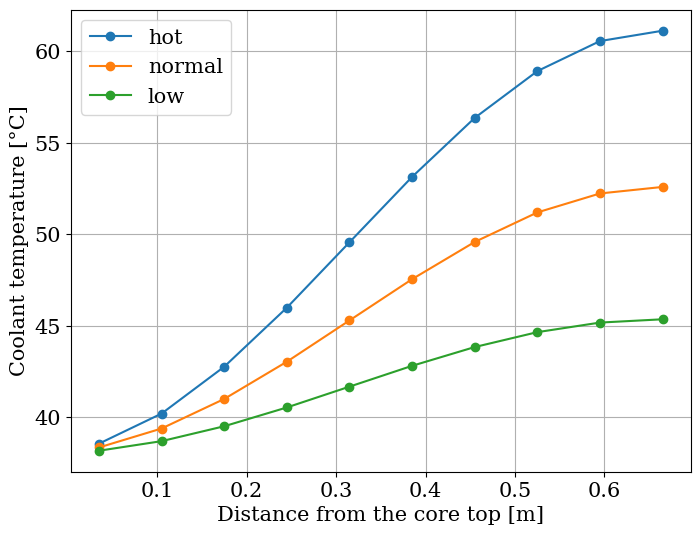

hot outlet: 61.1 °C
normal outlet: 52.6 °C
low outlet: 45.4 °C


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for k in HEATED:
    ch = refs["channels"][k]
    ax.plot(ch.centers, state[ch.name]["T_cool"], marker="o", label=k)
ax.set_xlabel("Distance from the core top [m]")
ax.set_ylabel(r"Coolant temperature [°C]")
ax.legend()
ax.grid()
plt.show()
for k in HEATED:
    print(f"{k} outlet: {state[refs['channels'][k].name]['T_cool'][-1]:.1f} °C")

The hot channel leaves the core at about 61 °C and the normal channels at about 53 °C, far below the saturation temperature at the pressure under 8 m of water. The next example, *Both Pumps Trip*, starts the transient from exactly this state: the pumps lose their head, the flywheels carry the flow down, the reactor trips on low flow, the flapper opens, and the core reverses into natural circulation through the pool.